# 01 — IDD Dataset Loading
Project: Privacy-Preserving Edge AI Framework for Intelligent Transportation

Purpose: Load the IDD Detection dataset, read the train/validation/test splits, and prepare image and annotation paths.

In [10]:
# CELL 2: Imports and paths
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import xml.etree.ElementTree as ET

ROOT = Path("/workspace/IDD_Detection")
PROJECT = Path("/workspace/ITS_Project")

print("Dataset:", ROOT)
print("Project:", PROJECT)

Dataset: /workspace/IDD_Detection
Project: /workspace/ITS_Project


In [11]:
# CELL 3: Load dataset splits
splits = {
    name: [
        line.strip()
        for line in (ROOT / f"{name}.txt").read_text().splitlines()
        if line.strip()
    ]
    for name in ["train", "val", "test"]
}

for name, entries in splits.items():
    print(f"{name}: {len(entries):,} images")

train: 31,569 images
val: 10,225 images
test: 4,794 images


In [12]:
# CELL 4: Build image and annotation paths
def image_path(entry):
    return (ROOT / "JPEGImages" / entry).with_suffix(".jpg")

def annotation_path(entry):
    return (ROOT / "Annotations" / entry).with_suffix(".xml")

train_images = [image_path(x) for x in splits["train"]]
val_images = [image_path(x) for x in splits["val"]]
test_images = [image_path(x) for x in splits["test"]]

train_annotations = [annotation_path(x) for x in splits["train"]]
val_annotations = [annotation_path(x) for x in splits["val"]]

print("Training images:", len(train_images))
print("Validation images:", len(val_images))
print("Test images:", len(test_images))

Training images: 31569
Validation images: 10225
Test images: 4794


Sample: JPEGImages/frontFar/BLR-2018-03-22_17-39-26_2_frontFar/001542_r.jpg
Image size: (1280, 964)


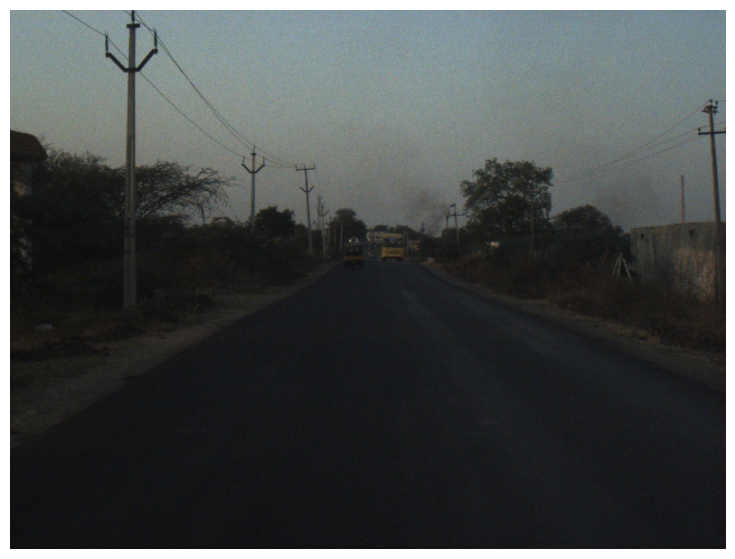

In [13]:
# CELL 5: Preview a training image
sample_path = next(p for p in train_images if p.is_file())

with Image.open(sample_path) as image:
    print("Sample:", sample_path.relative_to(ROOT))
    print("Image size:", image.size)
    plt.figure(figsize=(12, 7))
    plt.imshow(image)
    plt.axis("off")
    plt.show()

In [14]:
# CELL 6: Extract object class names from training annotations
class_counts = {}
annotated_images = 0
missing_annotations = 0

for xml_path in train_annotations:
    if not xml_path.is_file():
        missing_annotations += 1
        continue

    root = ET.parse(xml_path).getroot()
    annotated_images += 1

    for obj in root.findall("object"):
        name = obj.findtext("name", default="unknown").strip()
        class_counts[name] = class_counts.get(name, 0) + 1

print("Annotated training images:", annotated_images)
print("Missing training annotations:", missing_annotations)
print("Unique classes:", len(class_counts))

Annotated training images: 31569
Missing training annotations: 0
Unique classes: 15


In [15]:
# CELL 7: Object counts by class
class_df = (
    pd.DataFrame(class_counts.items(), columns=["Class", "Object_Count"])
    .sort_values("Object_Count", ascending=False)
    .reset_index(drop=True)
)

display(class_df)

,Class,Object_Count
0,motorcycle,78119
1,rider,73108
2,person,70319
3,car,65676
4,autorickshaw,24498
5,truck,20759
6,vehicle fallback,14992
7,bus,13829
8,traffic sign,9916
9,animal,4764


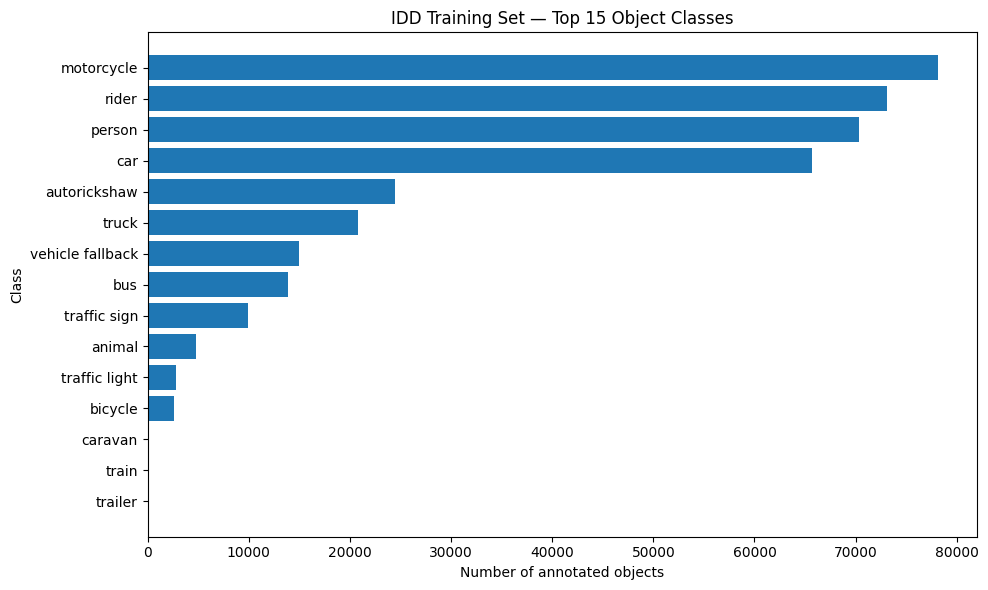

In [16]:
# CELL 8: Visualize the 15 most frequent classes
top_classes = class_df.head(15).sort_values("Object_Count")

plt.figure(figsize=(10, 6))
plt.barh(top_classes["Class"], top_classes["Object_Count"])
plt.xlabel("Number of annotated objects")
plt.ylabel("Class")
plt.title("IDD Training Set — Top 15 Object Classes")
plt.tight_layout()
plt.show()

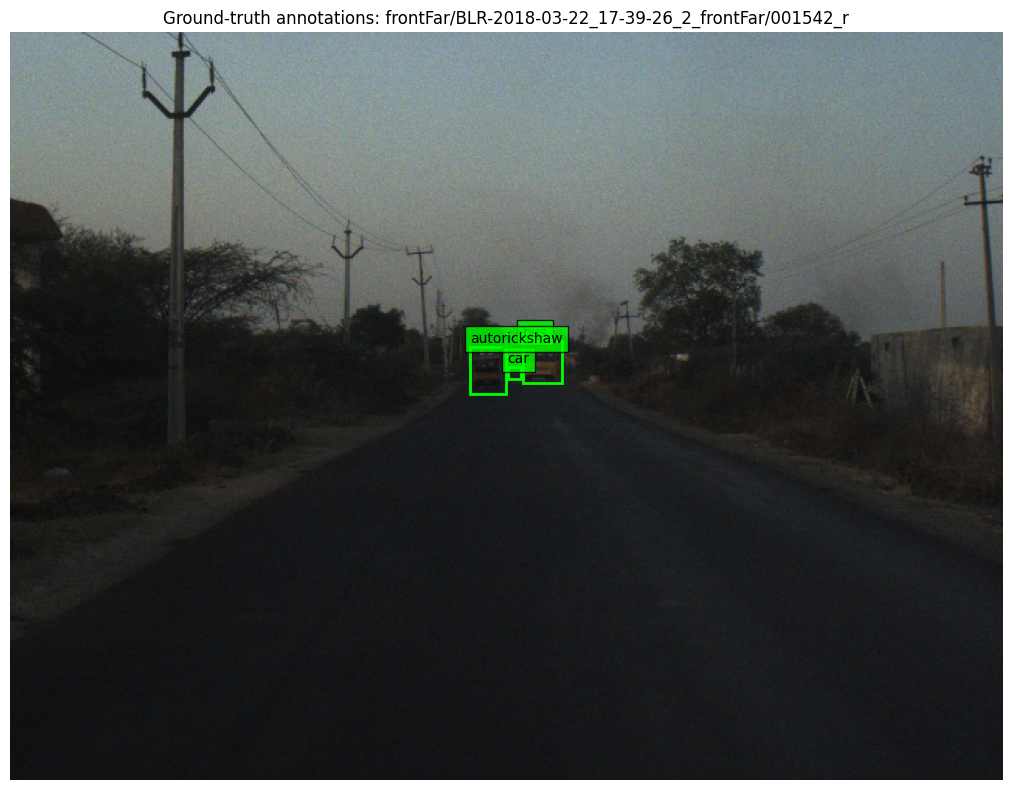

In [17]:
# CELL 9: Draw ground-truth bounding boxes on a sample image
sample_entry = next(
    entry for entry in splits["train"]
    if image_path(entry).is_file() and annotation_path(entry).is_file()
)

sample_image_path = image_path(sample_entry)
sample_xml_path = annotation_path(sample_entry)

with Image.open(sample_image_path) as image:
    image = image.convert("RGB")
    fig, ax = plt.subplots(figsize=(14, 8))
    ax.imshow(image)

    xml_root = ET.parse(sample_xml_path).getroot()

    for obj in xml_root.findall("object"):
        name = obj.findtext("name", default="unknown")
        box = obj.find("bndbox")

        if box is None:
            continue

        xmin = float(box.findtext("xmin"))
        ymin = float(box.findtext("ymin"))
        xmax = float(box.findtext("xmax"))
        ymax = float(box.findtext("ymax"))

        from matplotlib.patches import Rectangle
        ax.add_patch(
            Rectangle(
                (xmin, ymin),
                xmax - xmin,
                ymax - ymin,
                fill=False,
                edgecolor="lime",
                linewidth=2
            )
        )
        ax.text(
            xmin, max(0, ymin - 5), name,
            color="black",
            bbox=dict(facecolor="lime", alpha=0.8)
        )

    ax.axis("off")
    plt.title(f"Ground-truth annotations: {sample_entry}")
    plt.tight_layout()
    plt.show()

In [18]:
# CELL 10: Save dataset metadata for subsequent notebooks
import json

metadata = {
    "dataset_root": str(ROOT),
    "splits": {
        name: len(entries)
        for name, entries in splits.items()
    },
    "annotation_status": {
        "train": "annotated",
        "val": "annotated",
        "test": "unannotated"
    },
    "classes": sorted(class_counts.keys()),
    "training_object_counts": class_counts,
    "annotated_training_images": annotated_images
}

metadata_path = PROJECT / "configs" / "idd_metadata.json"
metadata_path.parent.mkdir(parents=True, exist_ok=True)
metadata_path.write_text(json.dumps(metadata, indent=2))

print("Metadata saved to:", metadata_path)
print("Classes recorded:", len(metadata["classes"]))

Metadata saved to: /workspace/ITS_Project/configs/idd_metadata.json
Classes recorded: 15
